# Лабораторная работа №1
Рабочее окружение. Командная строка Linux.

Монгуш Темир Мергенович · ИУ5-35Б · Вариант 11



[Условие](https://github.com/junaart/System_programming/blob/master/Lab_1/Lab_1.ipynb)

Ячейки выполняются сверху вниз. Проверено в Linux x86-64 с FASM.

## Подготовка

In [1]:
%%bash
set -e
if ! dpkg -s fasm binutils gcc file gdb gcc-multilib libc6-dev-i386 mc >/dev/null 2>&1; then
    SUDO=()
    if [ "$(id -u)" -ne 0 ]; then SUDO=(sudo); fi
    "${SUDO[@]}" apt-get update -qq
    "${SUDO[@]}" env DEBIAN_FRONTEND=noninteractive apt-get install -y -qq fasm binutils gcc file gdb gcc-multilib libc6-dev-i386 mc
fi
mkdir -p Lab_1/sandbox
uname -sm
fasm | head -n 1
gcc --version | head -n 1

Linux x86_64
flat assembler  version 1.73.32
gcc (Debian 14.2.0-19) 14.2.0


## 1. Программа на ассемблере: вывод ФИО, 32 бита

In [2]:
%%writefile Lab_1/sandbox/Монгуш.asm
; FASM, Linux x86, 32 бита, UTF-8
format ELF
public _start
section '.data' writeable
    message db 'Монгуш', 10
            db 'Темир', 10
            db 'Мергенович', 10
    message_length = $ - message
section '.text' executable
_start:
    ; write(1, message, message_length)
    mov eax, 4              ; системный вызов write
    mov ebx, 1              ; стандартный вывод
    mov ecx, message        ; адрес текста
    mov edx, message_length ; длина текста в байтах
    int 0x80
    ; exit(0)
    mov eax, 1              ; системный вызов exit
    mov ebx, 0              ; успешное завершение
    int 0x80

Writing Lab_1/sandbox/Монгуш.asm


## 2. Программа на C

In [3]:
%%writefile Lab_1/sandbox/С_version.c
#include <stdio.h>
int main(void)
{
    puts("Монгуш");
    puts("Темир");
    puts("Мергенович");
    return 0;
}

Writing Lab_1/sandbox/С_version.c


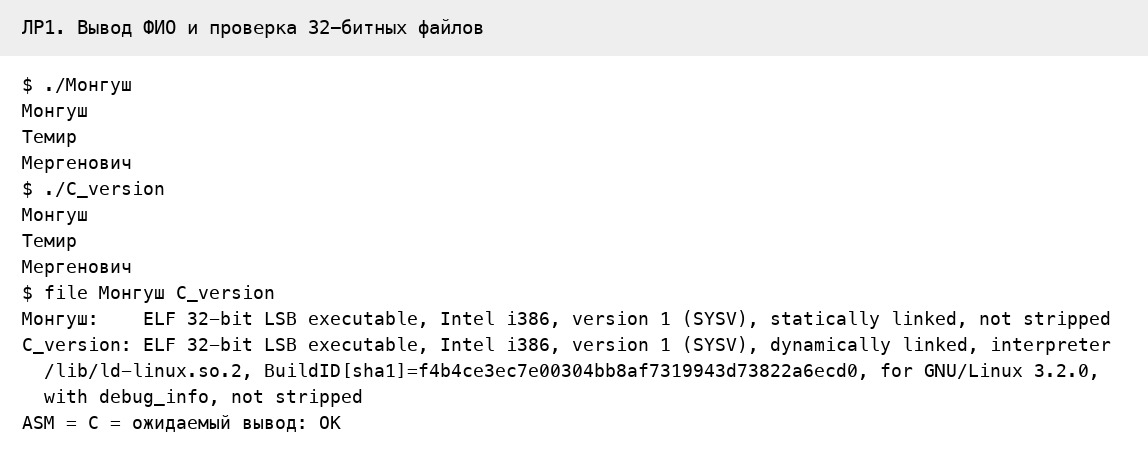

In [4]:
%%bash
set -e
cd Lab_1/sandbox
fasm Монгуш.asm Монгуш.o >/dev/null
ld -m elf_i386 Монгуш.o -o Монгуш
gcc -m32 -g -O0 -fno-pie -no-pie С_version.c -o C_version
echo '$ ./Монгуш'
./Монгуш
echo '$ ./C_version'
./C_version
echo '$ file Монгуш C_version'
file Монгуш C_version
./Монгуш > asm_result.txt
./C_version > c_result.txt
printf '%s\n' Монгуш Темир Мергенович > expected.txt
cmp expected.txt asm_result.txt
cmp asm_result.txt c_result.txt
echo 'ASM = C = ожидаемый вывод: OK'

## 3. Дизассемблирование в gdb

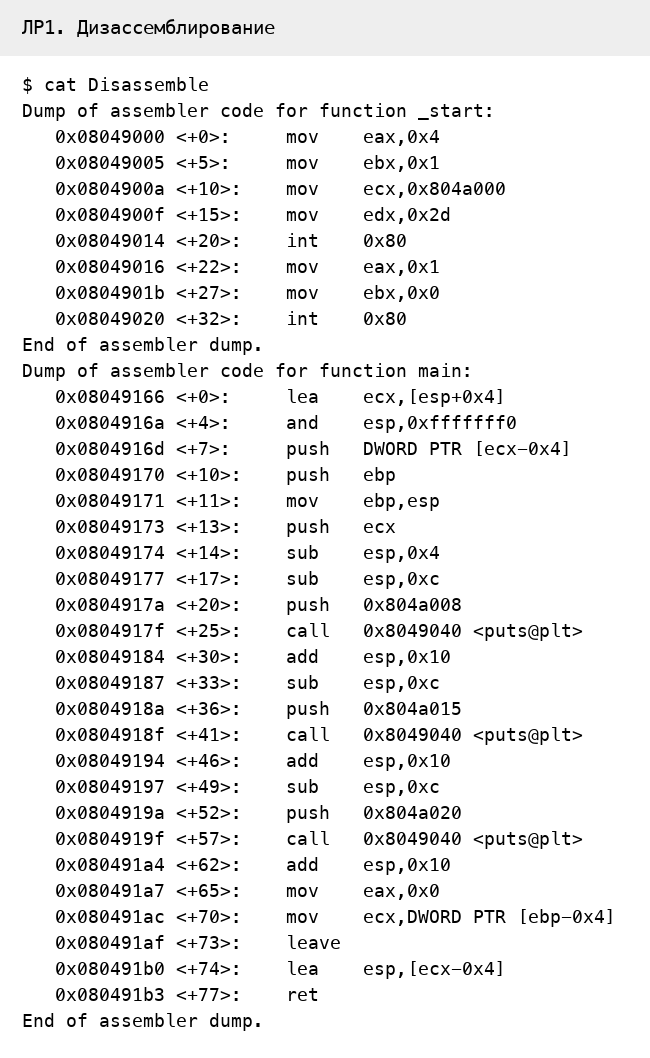

In [5]:
%%bash
set -e
cd Lab_1/sandbox
gdb -q -batch -ex 'set disassembly-flavor intel' -ex 'disassemble _start' Монгуш > Disassemble
gdb -q -batch -ex 'set disassembly-flavor intel' -ex 'disassemble main' C_version >> Disassemble
echo '$ cat Disassemble'
cat Disassemble

## 4. Работа с файлами — пункты 1–12

In [6]:
%%writefile Lab_1/Work_files
#!/bin/bash
set -e
cd "$(dirname "$0")"
mkdir -p Work
cd Work
mkdir -p 'Лабораторная работа №1!' 'ФИО' 'Контрольная работа №1!'
chmod 772 'Контрольная работа №1!'
chmod 200 'ФИО'
stat -c '%a %n' 'Контрольная работа №1!' 'ФИО'
touch 'Text @1' 'Text $2' 'Text  #3'
printf '%s\n' 'Птица говорун отличается умом и сообразительностью!' \
    'Отличается умом, отличается сообразительностью...' > 'Text @1'
cat 'Text @1' > 'Text $2'
mv -f 'Text $2' 'Лабораторная работа №1!/'
# Для работы внутри каталога необходимы права x; в конце возвращаем 200.
chmod 700 'ФИО'
cp 'Text @1' 'ФИО/'
gzip -kf 'Text @1' 'Text  #3'
tar -cf MyAchiv 'Text @1.gz' 'Text  #3.gz'
head -n 1 'Text @1' > 'Text  #3'
printf '%s\n' 'Будь осторожен! Преступник вооружен!' >> 'Text  #3'
tac 'Text @1' > 'ФИО/Result_one'
mv -f 'ФИО/Result_one' 'ФИО/Result_two'
find 'ФИО' -mindepth 1 -maxdepth 1 -name 'T*' -printf '%f\n' \
    > 'Лабораторная работа №1!/Result_3'
uname -a >> 'Лабораторная работа №1!/Result_3'
date >> 'Лабораторная работа №1!/Result_3'
printf '\nText  #3:\n'
cat 'Text  #3'
printf '\nResult_two:\n'
cat 'ФИО/Result_two'
printf '\nMyAchiv:\n'
tar -tf MyAchiv
cmp 'Text @1' 'ФИО/Text @1'
cmp 'Text @1' 'Лабораторная работа №1!/Text $2'
tac 'Text @1' | cmp - 'ФИО/Result_two'
gzip -t 'Text @1.gz' 'Text  #3.gz'
chmod 200 'ФИО'
stat -c '%a %n' 'Контрольная работа №1!' 'ФИО'
echo 'Проверки файлов: OK'

Writing Lab_1/Work_files


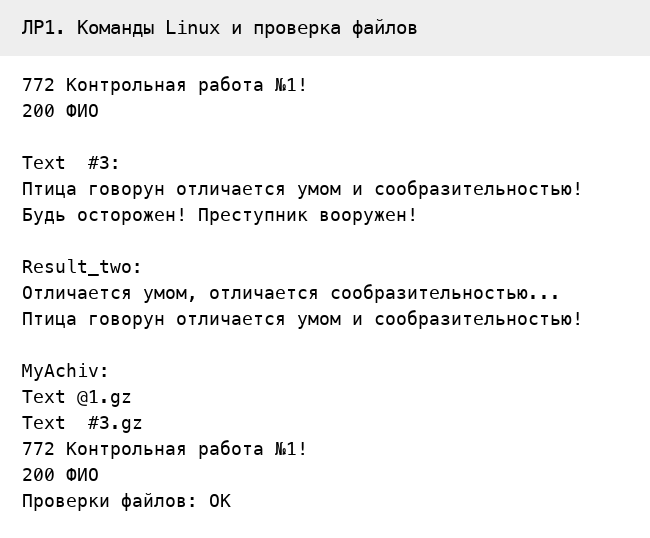

In [7]:
%%bash
set -e
bash Lab_1/Work_files

## Репозиторий
[Lab_1 на GitHub](https://github.com/tem1rka/System_programming/tree/main/Lab_1)